# Machine Learning Homework - Group 22
# Notebook 1 - Import & Explore

**Objective**: Inspect `train.csv` and the auxiliary `clientes.csv`, describe the
observations and variables, provide descriptive statistics, check data quality and
inconsistencies and explore univariate and multivariate relationships.

**Contents**:

1. Environment
2. Loading the files
3. Structural analysis of train dataset
4. Column roles
5. Readable labels for columns
6. Duplicates and uniqueness of identifiers
7. Target and baseline to beat
8. Missing data
9. Invalid values
10. Statistical analysis of numeric features
11. Histograms and outlier fences
12. Statistical analysis for categorical features
13. Correlation between numeric features and the target
14. Correlation among numeric features
15. Correlation between categorical features and the target
16. Customer metadata
17. Train vs test
18. Summary

No analysis here drops features or rows: every table and figure covers all
29 numeric and all 6 categorical features.

### Cell 1 - Environment:
This is where the import takes place, the paths are fixed and a visual theme is chosen for all the figures.

`Path.cwd()` is the only path helper used, because notebooks run from inside `01_notebooks/`.
The `data/` path printed at the bottom confirms the folder layout.
A `guide` function is created to append a "how to read" caption to the axes title, so a figure still explains itself
when it is printed on a page or opened on its own.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import chi2_contingency, pointbiserialr
from scipy.stats.contingency import association
pd.set_option('display.max_columns', None)


ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
FIG_DIR = ARTIFACTS_DIR / "figures"

PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"

def guide(ax, text):
    ax.set_title(ax.get_title() + "\n" + text, fontsize=9)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print(" Repo root:", ROOT)
print(" Data dir :", DATA_DIR)

Environment ready.
 Repo root: /Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22
 Data dir : /Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/data


### Cell 2 - Loading the files:
Read the raw inputs and their dimensions and confirm the target column exists where it should.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
TARGET = "repeat_purchase_90d"

print("Dimensions (rows, columns):")
print("  train        :", train.shape)
print("  test         :", test.shape)
print("  clientes     :", clientes.shape)

print("\nTarget info:")
print("  target in train :", TARGET in train.columns)
print("  target in test  :", TARGET in test.columns)
print("  target values   :", sorted(train[TARGET].unique().tolist()))

Dimensions (rows, columns):
  train        : (6534, 39)
  test         : (986, 38)
  clientes     : (1143, 13)

Target info:
  target in train : True
  target in test  : False
  target values   : [0, 1]


### Cell 3 - Structural analysis of train dataset:
See what is actually in the data before classifying anything.

In [3]:
print("Train columns and data types:")
print(train.dtypes.to_string())
print("\nFirst 5 rows of train:")
train.head()

Train columns and data types:
Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purc

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


### Cell 4 - Column roles:
Decide how each column will be treated: identifier, date, numeric or categorical (target already identified in Cell 2).

From the previous cell, it can be observed that `purchase_date` is stored as string instead of datetime. Let's also compare the `train` and `test` columns once the target is removed, to make sure there aren't any exclusive ones.

In [4]:
id_cols = ["ID", "customer_id"]
date_cols = ["purchase_date"]

numeric_all = train.select_dtypes("number").columns.tolist()
categorical_cols = [c for c in train.select_dtypes(include=["object"]).columns if c not in date_cols]
numeric_cols = [c for c in numeric_all if c != TARGET and c not in id_cols]

print("\nColumns by role in train:")
print(f"identifiers        : {len(id_cols)}, {id_cols}")
print(f"target             : {TARGET}")
print(f"date (as string)   : {date_cols}")
print(f"numeric            : {len(numeric_cols)}, {numeric_cols}")
print(f"categorical        : {len(categorical_cols)}, {categorical_cols}")

only_train = sorted(set(train.columns) - set(test.columns) - {TARGET})
only_test = sorted(set(test.columns) - set(train.columns))
print("\nSchema alignment:")
print("columns only in train (besides target):", only_train if only_train else "none")
print("columns only in test                  :", only_test if only_test else "none")


Columns by role in train:
identifiers        : 2, ['ID', 'customer_id']
target             : repeat_purchase_90d
date (as string)   : ['purchase_date']
numeric            : 29, ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'random_noise']
categorical        : 6, ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

Schema alignment:
columns only in train (besides target): none
columns only in test           

/var/folders/c_/vmpp1ncj395_01xzrfccnm200000gn/T/ipykernel_26463/2845436645.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = [c for c in train.select_dtypes(include=["object"]).columns if c not in date_cols]


### Cell 5 - Readable labels for columns:
Map each raw column name to a label used in all tables and figures in this notebook using a dictionary (`FEATURE_LABELS`).

`clean_label` is a function that converts column names into more readable labels. It first checks for a custom label in the dictionary. If there isn't one, it replaces underscores with spaces and uppercases the first letter of each word. `train columns without an explicit label: none` proves that there are no columns left to label.

In [5]:
FEATURE_LABELS = {
    "Total a Pagar": "Total Payable (EUR)",
    "Total Bruto": "Gross Total (EUR)",
    "Total Liquido": "Net Total (EUR)",
    "Total Imp_": "Tax Total (EUR)",
    "Total Portes": "Shipping Cost (EUR)",
    "Total Desc_ Global": "Global Discount (EUR)",
    "Total Desc_ Linha": "Line Discount (EUR)",
    "Custo": "Cost of Goods (EUR)",
    "N_ Detalhes": "Number of Line Items",
    "invoice_count_current_purchase": "Invoice Count in Purchase",
    "repeat_purchase_90d": "Repeat Purchase within 90 Days",
    "days_since_previous_purchase": "Days Since Previous Purchase",
    "customer_tenure_days": "Customer Tenure (Days)",
    "prior_purchase_count": "Prior Purchase Count",
    "prior_total_spend": "Prior Total Spend (EUR)",
    "prior_mean_purchase_value": "Prior Mean Purchase Value (EUR)",
    "prior_std_purchase_value": "Prior Std Purchase Value (EUR)",
    "prior_min_purchase_value": "Prior Min Purchase Value (EUR)",
    "prior_max_purchase_value": "Prior Max Purchase Value (EUR)",
    "prior_mean_gap_days": "Prior Mean Purchase Gap (Days)",
    "prior_std_gap_days": "Prior Std Purchase Gap (Days)",
    "purchase_count_30d": "Purchase Count (Past 30d)",
    "spend_30d": "Spend (Past 30d, EUR)",
    "purchase_count_90d": "Purchase Count (Past 90d)",
    "spend_90d": "Spend (Past 90d, EUR)",
    "purchase_count_180d": "Purchase Count (Past 180d)",
    "spend_180d": "Spend (Past 180d, EUR)",
    "purchase_count_365d": "Purchase Count (Past 365d)",
    "spend_365d": "Spend (Past 365d, EUR)",
    "random_noise": "Random Noise",
    "customer_id": "Customer ID",
    "customer_since_year": "Customer Since (Year)",
    "payment_type": "Payment Method",
    "transport_method": "Transport Method",
    "commercial_zone": "Commercial Zone",
    "salesperson": "Salesperson Code",
    "warehouse": "Warehouse Location",
    "document_series": "Document Series",
    "purchase_date": "Purchase Date",
    "commercial_region": "Commercial Region",
    "country_or_region": "Country / Region",
}


def clean_label(col):
    return FEATURE_LABELS.get(col, col.replace("_", " ").title())


uncovered = [c for c in train.columns if c not in FEATURE_LABELS and c != "ID"]
print("Labels defined for", len(FEATURE_LABELS), "columns.")
print("train columns without an explicit label:", uncovered if uncovered else "none (ID excluded)")

Labels defined for 41 columns.
train columns without an explicit label: none (ID excluded)


### Cell 6 - Duplicates and uniqueness of identifiers:
Check for repeated id's and duplicated rows within and between `train` and `test`.

Checking duplicates within `train` dataset is important because repeated observations may bias the model by giving certain patterns more significance, leading to overfitting. Identifying identical rows between the `train` and `test` datasets is essential to prevent data leakage, which could lead to an overestimation of the model's performance. In addition, a brief statistical analysis of the number of registered customers and their transactions is performed on the `train` dataset (mean, median, maximum and minimium).

In [6]:
print("Duplicates/uniqueness:")
print(" train exact duplicate rows:", int(train.duplicated().sum()))
print(" test exact duplicate rows :", int(test.duplicated().sum()))
print(" clientes duplicate rows   :", int(clientes.duplicated().sum()))
print(" train ID unique            :", bool(train["ID"].nunique() == len(train)))
print(" test ID unique             :", bool(test["ID"].nunique() == len(test)))
print(" clientes customer_id unique:", bool(clientes["customer_id"].nunique() == len(clientes)))


measured = [c for c in test.columns if c in train.columns and c != "ID"]
print("\nDuplicate transactions (ID and target excluded):")
print(" train rows involved in duplications:", train.duplicated(subset=measured, keep=False).sum())
print(" train duplicates (surplus)         :", train.duplicated(subset=measured).sum())
print(" test rows involved in duplications :", test.duplicated(subset=measured, keep=False).sum())
print(" test duplicates (surplus)          :", test.duplicated(subset=measured).sum())
train_keys = pd.MultiIndex.from_frame(train[measured])
test_keys = pd.MultiIndex.from_frame(test[measured])
print(" test rows identical to any training row:", test_keys.isin(train_keys).sum())
print("-> no test transaction is a copy of a training one, so the two files are really separate sales")

per_customer = train["customer_id"].value_counts()
print("\nUnique customers:", len(per_customer))
print(f"Transactions per customer (train): mean={round(per_customer.mean(), 1)}, median={per_customer.median()}, max={per_customer.max()}, min={per_customer.min()}")

print("\nCustomers repeat across rows, so a purely random split can place the same customer in both train and validation folds.")
print("\nIn Notebook 4, there will be a grouped or temporal check.")
print("\nTrain rows involved in duplications:")
display(train[train.duplicated(subset=measured, keep=False)])

Duplicates/uniqueness:
 train exact duplicate rows: 0
 test exact duplicate rows : 0
 clientes duplicate rows   : 0
 train ID unique            : True
 test ID unique             : True
 clientes customer_id unique: True

Duplicate transactions (ID and target excluded):
 train rows involved in duplications: 20
 train duplicates (surplus)         : 12
 test rows involved in duplications : 0
 test duplicates (surplus)          : 0
 test rows identical to any training row: 0
-> no test transaction is a copy of a training one, so the two files are really separate sales

Unique customers: 610
Transactions per customer (train): mean=10.7, median=4.0, max=277, min=1

Customers repeat across rows, so a purely random split can place the same customer in both train and validation folds.

In Notebook 4, there will be a grouped or temporal check.

Train rows involved in duplications:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000457,NaN
484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000560,NaN
582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000678,NaN
748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000870,NaN
839,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000983,NaN
2036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10002381,NaN
2733,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003209,NaN
3178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,334782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003718,NaN
3573,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,239651,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004187,NaN
3804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004463,NaN


Looking at the rows involved in duplications, we assume that all those rows result from errors in the dataset that we are unaware of, since there are no features that provide information about the transactions (except for the IDs and the target).
From the transactions per customer analysis, the difference between the mean and median suggests a right-skewed distribution over a wide range, from 1 to 277 transactions per customer.

### Cell 7 - Target and the baseline to beat:
Analyse the distribution of target classes by calculating counts, shares, the majority-class baseline and majority/minority ratio, illustrated by a bar chart.

Target: repeat_purchase_90d


,Count,Share (%),Label
Class,,,
0,2880,44.08,no repeat
1,3654,55.92,repeat buyer



Majority-class baseline accuracy: 55.92%
Minority/majority ratio: 0.79


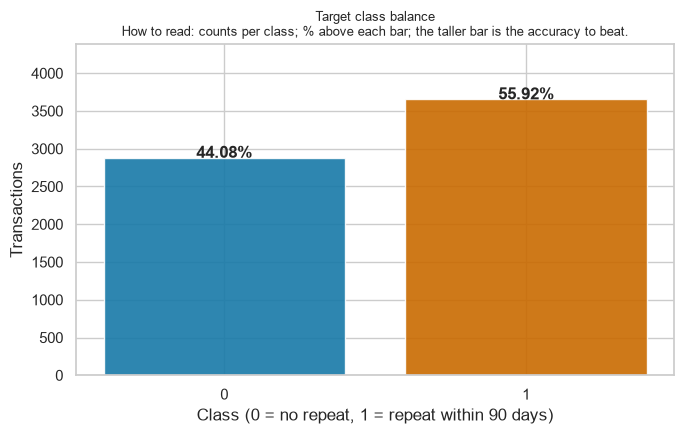

In [7]:
counts = train[TARGET].value_counts().sort_index()
share = train[TARGET].value_counts(normalize=True).sort_index()
baseline = share.max()
balance_ratio = share.min() / baseline

print("Target:", TARGET)
target_summary = pd.DataFrame({"Count": counts.values, "Share (%)": (share.values * 100).round(2),
                               "Label": ["repeat buyer" if cls == 1 else "no repeat" for cls in counts.index]}, index=counts.index)
target_summary.index.name = "Class"
display(target_summary)

print(f"\nMajority-class baseline accuracy: {baseline*100:.2f}%")
print(f"Minority/majority ratio: {balance_ratio:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([str(c) for c in counts.index], counts.values, color=[PLOT_BLUE, PLOT_ORANGE], alpha=0.9)

ax.set_ylim(0, counts.values.max() * 1.20)
ax.set_title("Target class balance")
ax.set_xlabel("Class (0 = no repeat, 1 = repeat within 90 days)")
ax.set_ylabel("Transactions")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{share.values[i] * 100:.2f}%", ha="center", fontsize=12, fontweight="bold")
guide(ax, "How to read: counts per class; % above each bar; the taller bar is the accuracy to beat.")
plt.savefig(FIG_DIR / "nb01_01_target_balance.png", dpi=200)
plt.tight_layout()
plt.show()

Looking at the results above, the target distribution is relatively balanced, with a ratio of 0.79, meaning that for every 100 customers who make a new purchase within 90 days, 79 do not. Also, the majority-class baseline accuracy is 55.92%, so any model we develop should achieve a higher accuracy than this.

### Cell 8 - Missing data:
Understand the missing values in our datasets, across columns in `train`, `test` and `clientes` datasets, as well as the number of missing values per row in the `train` dataset.

We also search for a pattern between recency missing values and customers with no previous purchases.

In [8]:
miss = pd.DataFrame({"train count": train.isna().sum(), "train rows %": train.isna().sum()/len(train)*100,
                     "test count": test.isna().sum(), "test rows %": test.isna().sum()/len(test)*100})
miss = miss.sort_values("train rows %", ascending=False)
miss.insert(0, "label", [clean_label(c) for c in miss.index])
print("Train columns missingness:")
display(miss.round(2))

row_missing = train.isna().sum(axis=1)
print("\nTrain rows missingness:")
display(row_missing.value_counts().sort_index().to_frame())

print("\nClientes columns missingness:")
clientes_miss = pd.DataFrame({"count": clientes.isna().sum(), "rows %": (clientes.isna().sum()/len(clientes)*100).round(2)})
clientes_miss = clientes_miss[(clientes_miss["count"] > 0)].sort_values("count", ascending=False)
clientes_miss.insert(0, "label", [clean_label(c) for c in clientes_miss.index])
display(clientes_miss)

both = int(((train["days_since_previous_purchase"].isna()) & (train["prior_purchase_count"] == 0)).sum())
print("\nRecency and history pattern:")
print("  rows where recency is missing AND prior_purchase_count == 0:", both)

Train columns missingness:


,label,train count,train rows %,test count,test rows %
prior_std_gap_days,Prior Std Purchase Gap (Days),1478,22.62,69.0,7.00
prior_mean_gap_days,Prior Mean Purchase Gap (Days),1308,20.02,76.0,7.71
prior_std_purchase_value,Prior Std Purchase Value (EUR),1113,17.03,46.0,4.67
prior_mean_purchase_value,Prior Mean Purchase Value (EUR),862,13.19,52.0,5.27
days_since_previous_purchase,Days Since Previous Purchase,861,13.18,52.0,5.27
prior_min_purchase_value,Prior Min Purchase Value (EUR),668,10.22,22.0,2.23
prior_max_purchase_value,Prior Max Purchase Value (EUR),668,10.22,22.0,2.23
transport_method,Transport Method,261,3.99,30.0,3.04
spend_365d,"Spend (Past 365d, EUR)",260,3.98,30.0,3.04
payment_type,Payment Method,260,3.98,30.0,3.04



Train rows missingness:


,count
0,3929
1,1287
2,190
3,354
4,100
5,6
7,511
8,86
9,6
36,65



Clientes columns missingness:


,label,count,rows %
customer_type,Customer Type,1143,100.00
street,Street,598,52.32
island,Island,578,50.57
city,City,546,47.77
postal_code,Postal Code,170,14.87
municipality,Municipality,159,13.91
commercial_region,Commercial Region,114,9.97
postal_area,Postal Area,71,6.21
address,Address,6,0.52



Recency and history pattern:
  rows where recency is missing AND prior_purchase_count == 0: 603


The missing values analysis reveals that historical purchase-related features have the highest proportions of missing values, particularly `prior_std_gap_days` (22.62% of observations) and `prior_mean_gap_days` (20.02% of observations). A interesting observation is that the features with the most missing values are statistical measures (mean, standard deviation, maximum, minimum) rather than values or information about a transaction itself. While 3929 training observations have no missing values at all, more than 1000 already have one missing value, with 36 being the maximum number of missing values in a row (65 observations), suggesting a distinct missingness pattern. Furthermore, 603 observations have missing recency values and no previous purchases, indicating that missing recency values (`days_since_previous_purchase`) may be related to customers with no previous purchases (`prior_purchase_count`).

In clients dataset, `customer_type` is entirely missing and several geographic features have more than half of their values missing (`street`, `island` and `city`).

### Cell 9 - Invalid values:
Find values that are present but cannot be true (negative or extremely high values).

In [9]:
print("Columns with extremely high values (placeholders):")
extremely_high = pd.DataFrame({"Feature": [clean_label(c) for c in numeric_cols], "Train count": [(train[c]>1e8).sum() for c in numeric_cols],
                               "Test count": [(test[c]>1e8).sum() for c in numeric_cols], "Train max": [train[c].max() for c in numeric_cols],
                               "Test max": [test[c].max() for c in numeric_cols]}, index=numeric_cols)
extremely_high = extremely_high[(extremely_high["Train count"]>0) | (extremely_high["Test count"]>0)]
display(extremely_high)

print("\nColumns with negative values:")
negative = pd.DataFrame({"Feature": [clean_label(c) for c in numeric_cols], "Train count": [(train[c]<0).sum() for c in numeric_cols],
                         "Test count": [(test[c]<0).sum() for c in numeric_cols], "Train min": [train[c].min() for c in numeric_cols],
                         "Test min": [test[c].min() for c in numeric_cols], "Test max": [test[c].max() for c in numeric_cols]}, index=numeric_cols)
negative = negative[(negative["Train count"]>0) | (negative["Test count"]>0)]
display(negative)

Columns with extremely high values (placeholders):


,Feature,Train count,Test count,Train max,Test max
prior_mean_purchase_value,Prior Mean Purchase Value (EUR),16,2,1.000000e+09,1.000000e+09
spend_365d,"Spend (Past 365d, EUR)",15,2,1.000000e+09,1.000000e+09



Columns with negative values:


,Feature,Train count,Test count,Train min,Test min,Test max
days_since_previous_purchase,Days Since Previous Purchase,16,2,-4.000000,-4.000000,3.958000e+03
prior_mean_purchase_value,Prior Mean Purchase Value (EUR),16,2,-2478.658478,-440.744000,1.000000e+09
prior_mean_gap_days,Prior Mean Purchase Gap (Days),16,2,-4.000000,-4.000000,1.847000e+03
spend_365d,"Spend (Past 365d, EUR)",15,2,-159115.175535,-3856.640000,1.000000e+09
random_noise,Random Noise,3357,481,-3.529210,-3.887804,3.100647e+00


The analysis above reveals potentially invalid values in `train` and `test` datasets. The features `prior_mean_purchase_value` and `spend_365d` contain extremely high values (1 billion), most likely due to data errors (placeholder). Additionally, negative values appear in time intervals and spending features, in both `train` and `test`, obviously impossible values. Negative values in `random_noise` are not necessarily problematic, as its name says, this variable can naturally take both positive and negative values. We will explore its distribution in some cells below.

### Cell 10 - Statistical analysis of numeric features:
Describe mean, standard deviation, quantiles, skew and count of zeros of each numeric feature in `train` dataset.

Then, each column is standardised using the z-score, so they can all be compared in a single boxplot figure. The resulting values are clipped to the interval [-4, 4] to allow only for a clearer visualisation, preserving the original values for further cleaning and preprocessing.

Numeric feature summary (train) - all 29 features:


,label,count,mean,std,min,25%,50%,75%,max,skew,count of zeros,zeros %
Total a Pagar,Total Payable (EUR),6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04,4.21,0,0.00
Total Bruto,Gross Total (EUR),6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04,4.31,0,0.00
Total Liquido,Net Total (EUR),6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04,4.15,0,0.00
Total Imp_,Tax Total (EUR),6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03,4.84,213,3.26
Total Portes,Shipping Cost (EUR),6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02,19.55,5416,82.89
Total Desc_ Global,Global Discount (EUR),6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02,27.46,6359,97.32
Total Desc_ Linha,Line Discount (EUR),6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03,5.92,2441,37.36
Custo,Cost of Goods (EUR),6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03,4.61,486,7.44
N_ Detalhes,Number of Line Items,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02,2.98,0,0.00
invoice_count_current_purchase,Invoice Count in Purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00,6.44,0,0.00



Highly skewed (|skew| > 1.5) -> log1p candidates in notebook 2:
  Total Payable (EUR), Gross Total (EUR), Net Total (EUR), Tax Total (EUR), Shipping Cost (EUR), Global Discount (EUR), Line Discount (EUR), Cost of Goods (EUR), Number of Line Items, Invoice Count in Purchase, Days Since Previous Purchase, Prior Purchase Count, Prior Total Spend (EUR), Prior Mean Purchase Value (EUR), Prior Std Purchase Value (EUR), Prior Min Purchase Value (EUR), Prior Max Purchase Value (EUR), Prior Mean Purchase Gap (Days), Prior Std Purchase Gap (Days), Purchase Count (Past 30d), Spend (Past 30d, EUR), Purchase Count (Past 90d), Spend (Past 90d, EUR), Purchase Count (Past 180d), Spend (Past 180d, EUR), Purchase Count (Past 365d), Spend (Past 365d, EUR)

Zero-inflated (> 60% zeros) -> the 1.5*IQR boxplot rule is unreliable here:
  Shipping Cost (EUR), Global Discount (EUR), Purchase Count (Past 30d), Spend (Past 30d, EUR)


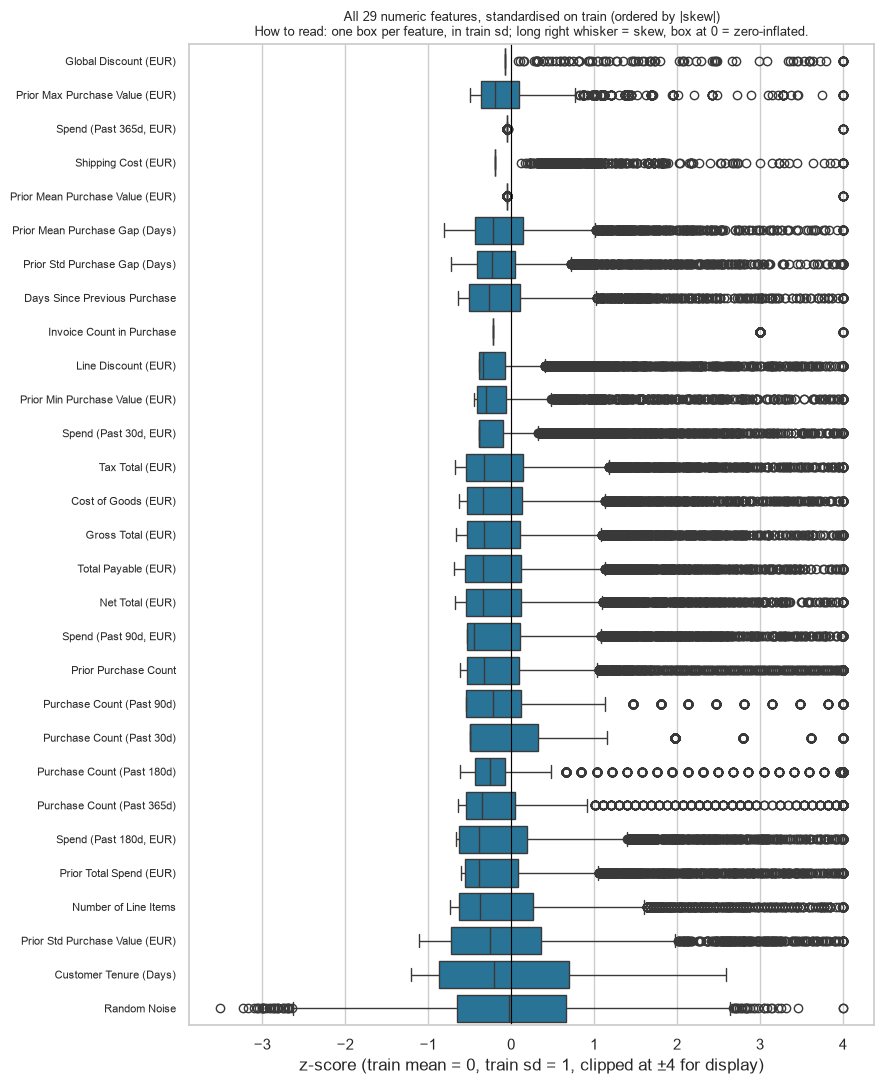

In [10]:
desc = train[numeric_cols].describe().T
desc["skew"] = train[numeric_cols].skew()
desc["count of zeros"] = (train[numeric_cols] == 0).sum()
desc["zeros %"] = (train[numeric_cols] == 0).sum() / len(train) * 100
desc.insert(0, "label", [clean_label(c) for c in desc.index])
print(f"Numeric feature summary (train) - all {len(numeric_cols)} features:")
display(desc.round(2))

skewed = desc.index[desc["skew"].abs() > 1.5].tolist()
zero_heavy = desc.index[desc["zeros %"] > 60].tolist()
print("\nHighly skewed (|skew| > 1.5) -> log1p candidates in notebook 2:")
print("  " + (", ".join(clean_label(c) for c in skewed) if skewed else "none"))
print("\nZero-inflated (> 60% zeros) -> the 1.5*IQR boxplot rule is unreliable here:")
print("  " + (", ".join(clean_label(c) for c in zero_heavy) if zero_heavy else "none"))


mu = train[numeric_cols].mean()
sd = train[numeric_cols].std()

z_train = ((train[numeric_cols] - mu) / sd).clip(-4, 4)
z_long = pd.melt(z_train, var_name="feature", value_name="z_score")
z_long["label"] = [clean_label(f) for f in z_long["feature"]]
order = [clean_label(c) for c in desc["skew"].abs().sort_values(ascending=False).index.tolist()]
z_long = z_long.assign(_o=[order.index(l) for l in z_long["label"]]).sort_values("_o")

fig, ax = plt.subplots(figsize=(9, 11))
sns.boxplot(data=z_long, y="label", x="z_score", orient="h", color=PLOT_BLUE, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"All {len(numeric_cols)} numeric features, standardised on train (ordered by |skew|)")
ax.set_xlabel("z-score (train mean = 0, train sd = 1, clipped at ±4 for display)")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: one box per feature, in train sd; long right whisker = skew, box at 0 = zero-inflated.")
plt.savefig(FIG_DIR / "nb01_02_numeric_boxplots.png", dpi=200)
plt.tight_layout()
plt.show()

The statistical analysis above reveals that most numeric features are strongly right-skewed, particularly `Total Desc_ Global`, `prior_max_purchase_value`, `spend_365d`, `Total Portes` and `prior_mean_purchase_value` (skew > 18). For features with skew > 1.5, we listed candidates for log1p outlier cleaning method in notebook 2.

`Total Portes`, `Total Desc_ Global`, `purchase_count_30d` and `spend_30d` have more than 60% zero values, suggesting that the IQR method may be unreliable for identifying outliers in these features. Looking at the features mentioned earlier with outliers equal to 10^9, it's easy to conclude that these values significantly shift the mean and make the boxplots difficult to visualize. Overall, this analysis proposes that some features may benefit from transformations to reduce skewness, after addressing invalid values during preprocessing.

### Cell 11 - Histograms and outlier fences:
Show the shape of every numeric feature and quantify what the IQR rule would call outlier.

Values greater than or equal to 10^8 are excluded so a placeholder we discussed in cell 9 do not interfere with the display of the histograms.

All 29 histograms in one figure:


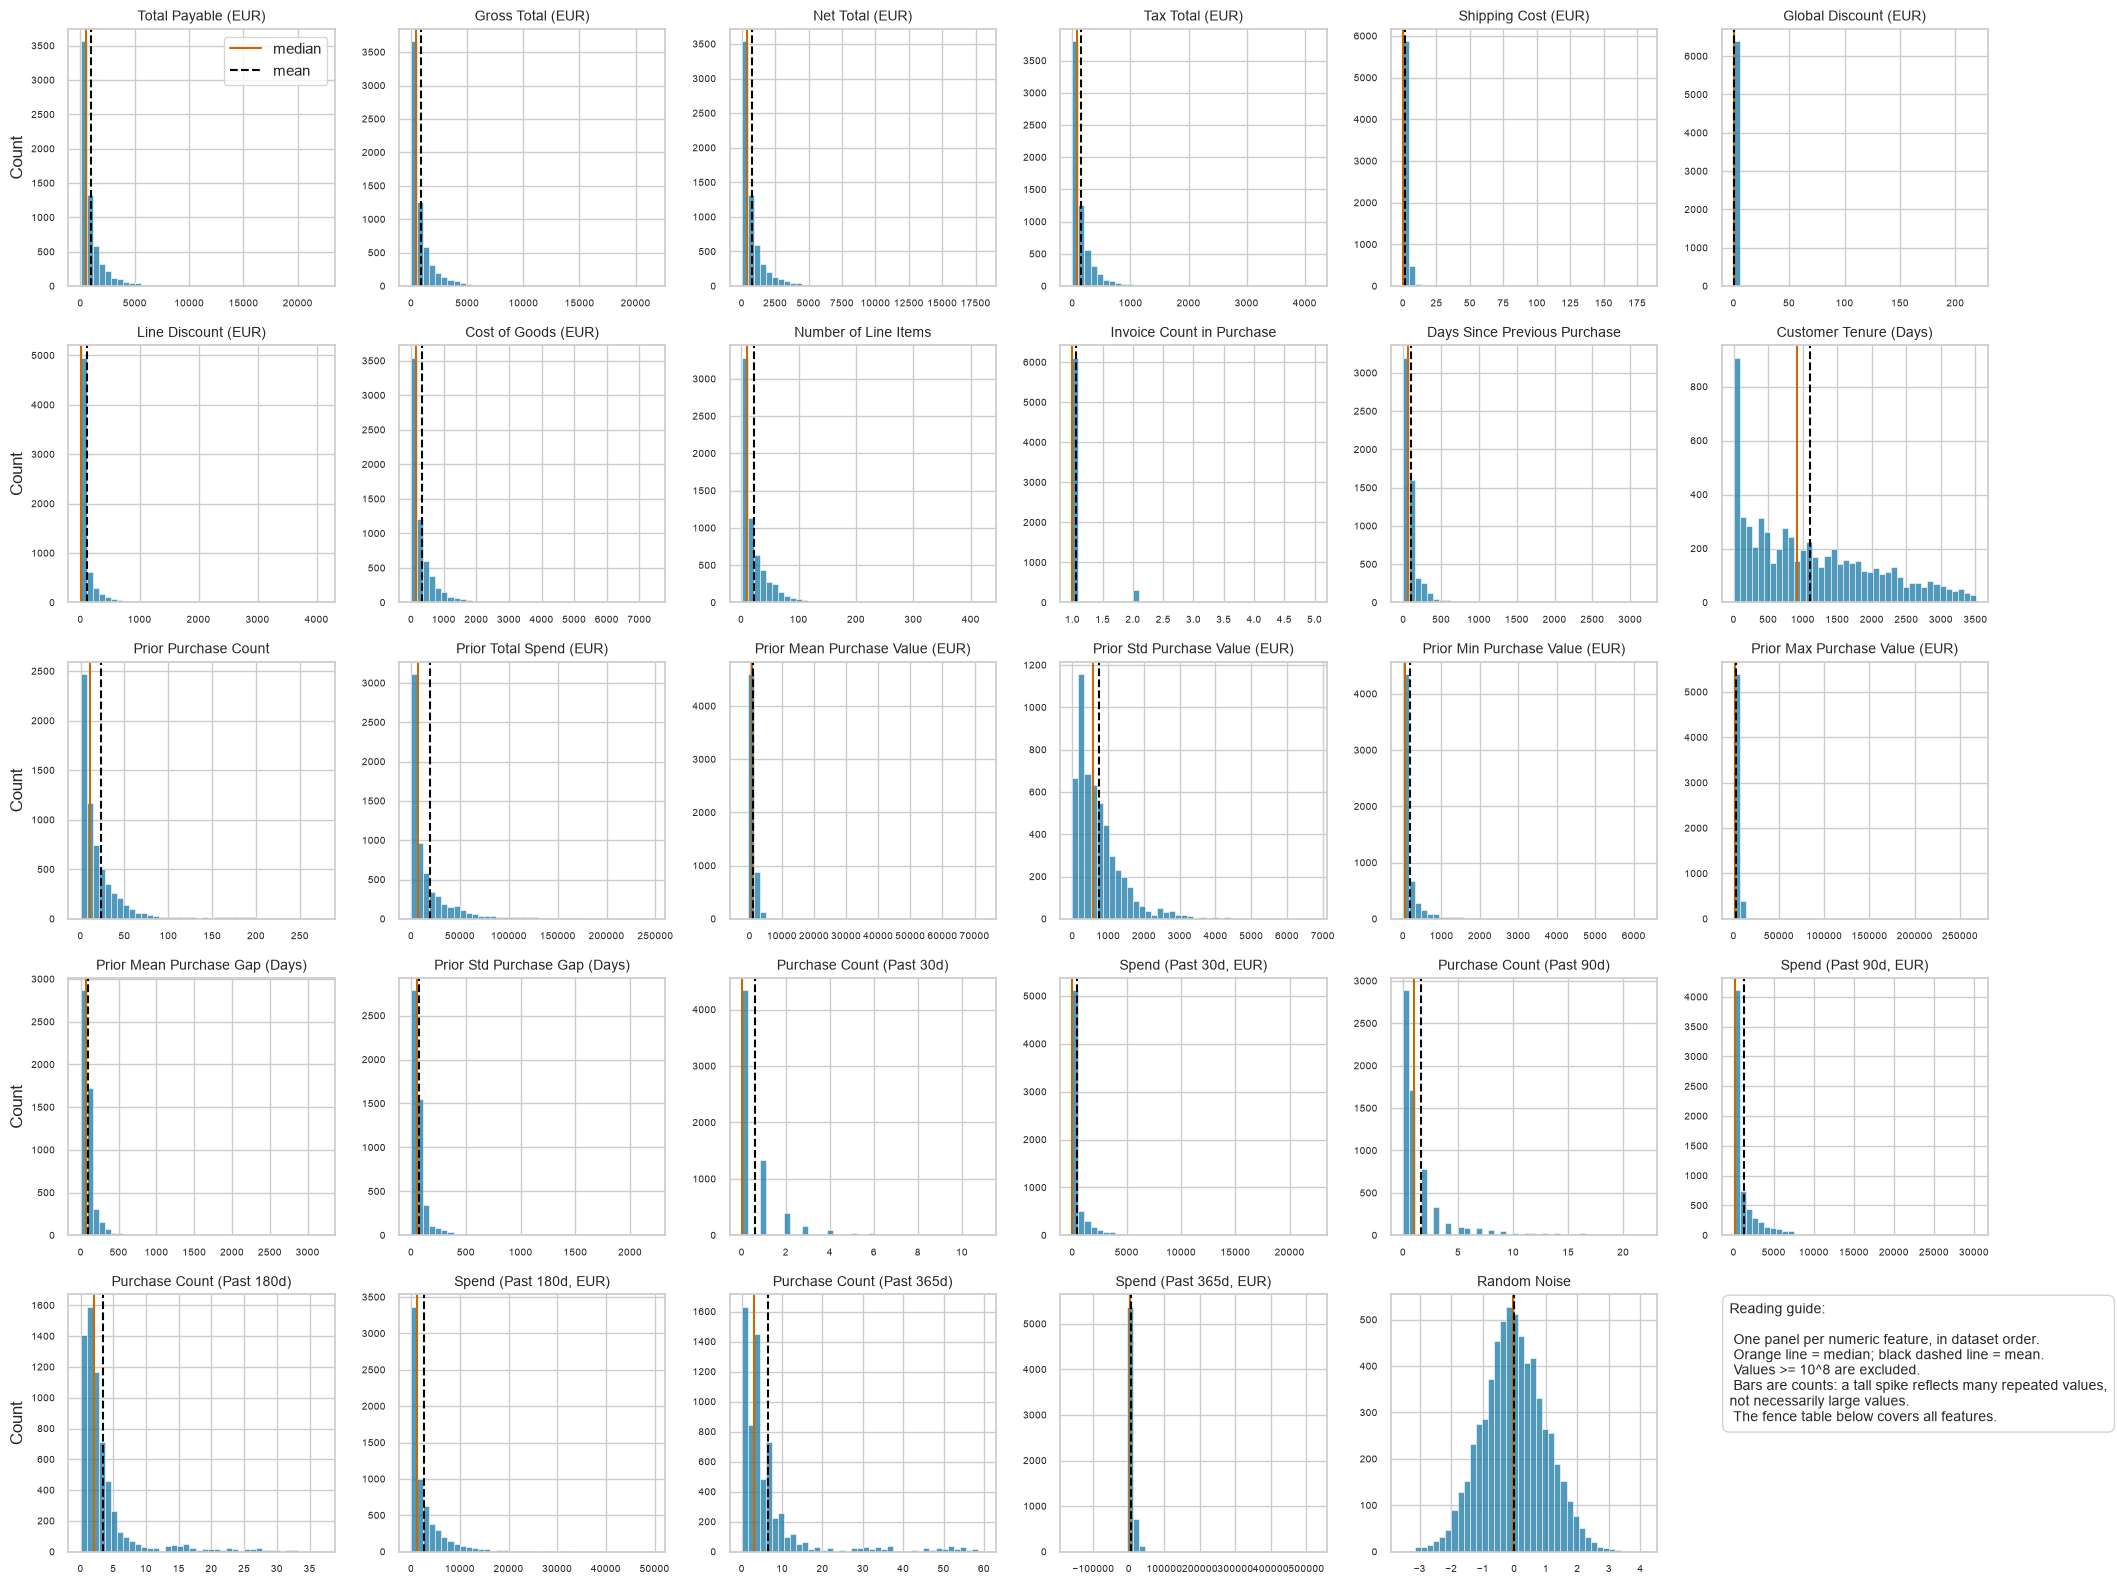


IQR outlier fences (1.5*IQR) on valid values (all numeric features, worst first):


,feature,q1,q3,fence_low,fence_high,count of outliers,outliers %
label,,,,,,,
"Spend (Past 30d, EUR)",spend_30d,0.00,338.24,-507.36,845.60,1060,16.39
Shipping Cost (EUR),Total Portes,0.00,0.00,0.00,0.00,1053,16.28
Line Discount (EUR),Total Desc_ Linha,0.00,92.28,-138.42,230.70,822,12.71
Prior Min Purchase Value (EUR),prior_min_purchase_value,15.45,162.61,-205.29,383.35,671,11.44
Purchase Count (Past 180d),purchase_count_180d,1.00,3.00,-2.00,6.00,737,11.39
"Spend (Past 90d, EUR)",spend_90d,0.00,1514.56,-2271.84,3786.40,661,10.22
Prior Total Spend (EUR),prior_total_spend,1505.55,21642.32,-28699.60,51847.48,642,9.92
Total Payable (EUR),Total a Pagar,188.92,1087.67,-1159.21,2435.80,592,9.15
Prior Std Purchase Gap (Days),prior_std_gap_days,32.74,78.63,-36.10,147.46,461,9.12


In [11]:
VALID_MAX = 1e8

def valid_values(col):
    s = train[col].dropna()
    return s[s < VALID_MAX]

print(f"All {len(numeric_cols)} histograms in one figure:")

N_COLS = 6
n_rows = math.ceil(len(numeric_cols) / N_COLS)
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.6 * N_COLS, 3.2 * n_rows))
for k, (ax, col) in enumerate(zip(axes.ravel(), numeric_cols)):
    s = valid_values(col)
    sns.histplot(s, bins=40, color=PLOT_BLUE, ax=ax)
    ax.axvline(s.median(), color=PLOT_ORANGE, linestyle="-", label="median")
    ax.axvline(s.mean(), color="black", linestyle="--", label="mean")
    ax.set_title(clean_label(col), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Count" if k % N_COLS == 0 else "")
    ax.tick_params(axis="x", labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    if k == 0:
        ax.legend(loc="upper right")

last_ax = axes.flat[-1]

last_ax.clear()
last_ax.set_axis_off()
last_ax.grid(False)
last_ax.set_facecolor("white")

note = ("Reading guide:\n\n"
    " One panel per numeric feature, in dataset order.\n"
    " Orange line = median; black dashed line = mean.\n"
    " Values >= 10^8 are excluded.\n"
    " Bars are counts: a tall spike reflects many repeated values,\n"
    "not necessarily large values.\n"
    " The fence table below covers all features.")

last_ax.text(0.03, 0.97, note, transform=last_ax.transAxes, ha="left", va="top", fontsize=10, wrap=True,
    bbox=dict(facecolor="white", edgecolor="lightgray", boxstyle="round,pad=0.5"))
plt.savefig(FIG_DIR / "nb01_03_histograms_all.png", dpi=200)
plt.tight_layout()
plt.show()

fence_rows = []
for col in numeric_cols:
    s = valid_values(col)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr
    outside = int(((s < lo) | (s > hi)).sum())
    fence_rows.append({"label": clean_label(col), "feature": col, "q1": q1, "q3": q3,
                       "fence_low": lo, "fence_high": hi, "count of outliers": outside,
                       "outliers %": outside/len(s)*100})
fences = pd.DataFrame(fence_rows).set_index("label").sort_values("outliers %", ascending=False)
print("\nIQR outlier fences (1.5*IQR) on valid values (all numeric features, worst first):")
display(fences.round(2))

As expected, the histograms show strong right-skewed asymmetry, with long right tails and most observations concentrated at lower values. The exception is `random_noise`, which has a well-defined Gaussian curve. The IQR analysis identifies substantial proportions of potential outliers, particularly in `spend_30d` (16.39%) and `Total Portes` (16.28%). However, these values are related to the high number of zeros (cell 10) present in these features, resulting in short IQR limits, as can be seen in `Total Portes`, where any value other than 0 is considered an outlier. On the other hand, due to the high variability of values in `customer_tenure_days`, this feature does not exhibit any outliers.

In general, these results should be interpreted with caution, since many of the flagged observations may represent actual purchases rather than data errors.

### Cell 12 - Statistical analysis for categorical features:
Analyse each level of each categorical variable.

Potential placeholders may be present, identified in strings such as "unknown", "-" or "?".

In [12]:
PLACEHOLDERS = {"?", "unknown", "n/a", "na", "none", "null", "nan", "-", ""}
for col in categorical_cols:
    vc = train[col].value_counts()
    print(f"\n{clean_label(col)} (raw: {col})")
    print(f"  levels: {train[col].nunique():3d} | rows with a value: {int(vc.sum())} | missing: {int(train[col].isna().sum())}")
    listing = pd.DataFrame({"level": vc.index.astype(str), "count": vc.values, "rows %": vc.values / len(train) * 100}).set_index("level")
    display(listing)
    ph = sorted({str(x).strip().lower() for x in vc.index if str(x).strip().lower() in PLACEHOLDERS})
    if ph:
        print("placeholder-like levels detected:", ph)


Payment Method (raw: payment_type)
  levels:   9 | rows with a value: 6274 | missing: 260


,count,rows %
level,,
Maybe Tomorrow Payment 7,4565,69.865320
Maybe Tomorrow Payment 12,991,15.166820
Maybe Tomorrow Payment 9,502,7.682890
Maybe Tomorrow Payment 10,134,2.050811
Maybe Tomorrow Payment 8,40,0.612182
Maybe Tomorrow Payment 2,21,0.321396
Maybe Tomorrow Payment 4,9,0.137741
Maybe Tomorrow Payment 11,8,0.122436
Maybe Tomorrow Payment 3,4,0.061218



Salesperson Code (raw: salesperson)
  levels:   9 | rows with a value: 6275 | missing: 259


,count,rows %
level,,
VLOOKUP Master 1,4054,62.044689
VLOOKUP Master 4,1461,22.359963
VLOOKUP Master 9,384,5.876951
VLOOKUP Master 7,201,3.076217
VLOOKUP Master 2,123,1.882461
VLOOKUP Master 3,30,0.459137
VLOOKUP Master 6,12,0.183655
VLOOKUP Master 5,7,0.107132
VLOOKUP Master 8,3,0.045914



Commercial Zone (raw: commercial_zone)
  levels:   5 | rows with a value: 6469 | missing: 65


...

,count,rows %
level,,
Maybe Tomorrow Delivery 72,1119,17.125803
Maybe Tomorrow Delivery 61,627,9.595960
Maybe Tomorrow Delivery 73,445,6.810530
Maybe Tomorrow Delivery 59,373,5.708601
Maybe Tomorrow Delivery 80,319,4.882155
...,...,...
Maybe Tomorrow Delivery 55,1,0.015305
Maybe Tomorrow Delivery 58,1,0.015305
Maybe Tomorrow Delivery 28,1,0.015305



Warehouse Location (raw: warehouse)
  levels:   2 | rows with a value: 6274 | missing: 260


,count,rows %
level,,
Final Excel Warehouse 1,6253,95.699418
Final Excel Warehouse 3,21,0.321396



Document Series (raw: document_series)
  levels:   3 | rows with a value: 6469 | missing: 65


,count,rows %
level,,
Ctrl Z Series 2,2738,41.903887
Ctrl Z Series 3,1903,29.124579
Ctrl Z Series 1,1828,27.976737


The categorical analysis reveals unbalanced distributions across several features, such as `commercial_zone` and `warehouse`, highly concentrated in a single level, accounting for approximately 96% of the observations. Similarly, `payment_type` and `salesperson` are dominated by a few levels, while `transport_method` has the highest cardinality (80 level), including many levels with only one observation. `document_series` exhibits a more balanced distribution across its three levels. There are missing values in all categorical features, but no placeholder-like levels were detected. Overall, these findings suggest that rare levels, highly concentrated features should be taken into account during preprocessing and feature selection.

### Cell 13 - Correlation between numeric features and the target:
Measure how much each numeric feature alone says about the target.

For each feature, it's used the point-biserial correlation coefficient (a Pearson between numeric and binary). The resultas are the correlation coefficient **r**, its absolute value, the p-value and the number of valid observations. Missing and invalid values are ommited so that the calculations are not distorted. A bar chart shows the correlation analysis, sorted in descending order by |r|.

Numeric association with target - all 29 features (point-biserial r)


,feature,r,|r|,p_value,n_used
label,,,,,
Purchase Count (Past 365d),purchase_count_365d,0.3403,0.3403,0.0000,6469
Purchase Count (Past 180d),purchase_count_180d,0.3342,0.3342,0.0000,6469
Purchase Count (Past 90d),purchase_count_90d,0.3279,0.3279,0.0000,6469
"Spend (Past 180d, EUR)",spend_180d,0.3010,0.3010,0.0000,6469
Prior Purchase Count,prior_purchase_count,0.2988,0.2988,0.0000,6469
"Spend (Past 90d, EUR)",spend_90d,0.2689,0.2689,0.0000,6469
Purchase Count (Past 30d),purchase_count_30d,0.2633,0.2633,0.0000,6469
Prior Total Spend (EUR),prior_total_spend,0.2619,0.2619,0.0000,6469
Prior Mean Purchase Gap (Days),prior_mean_gap_days,-0.2388,0.2388,0.0000,5210


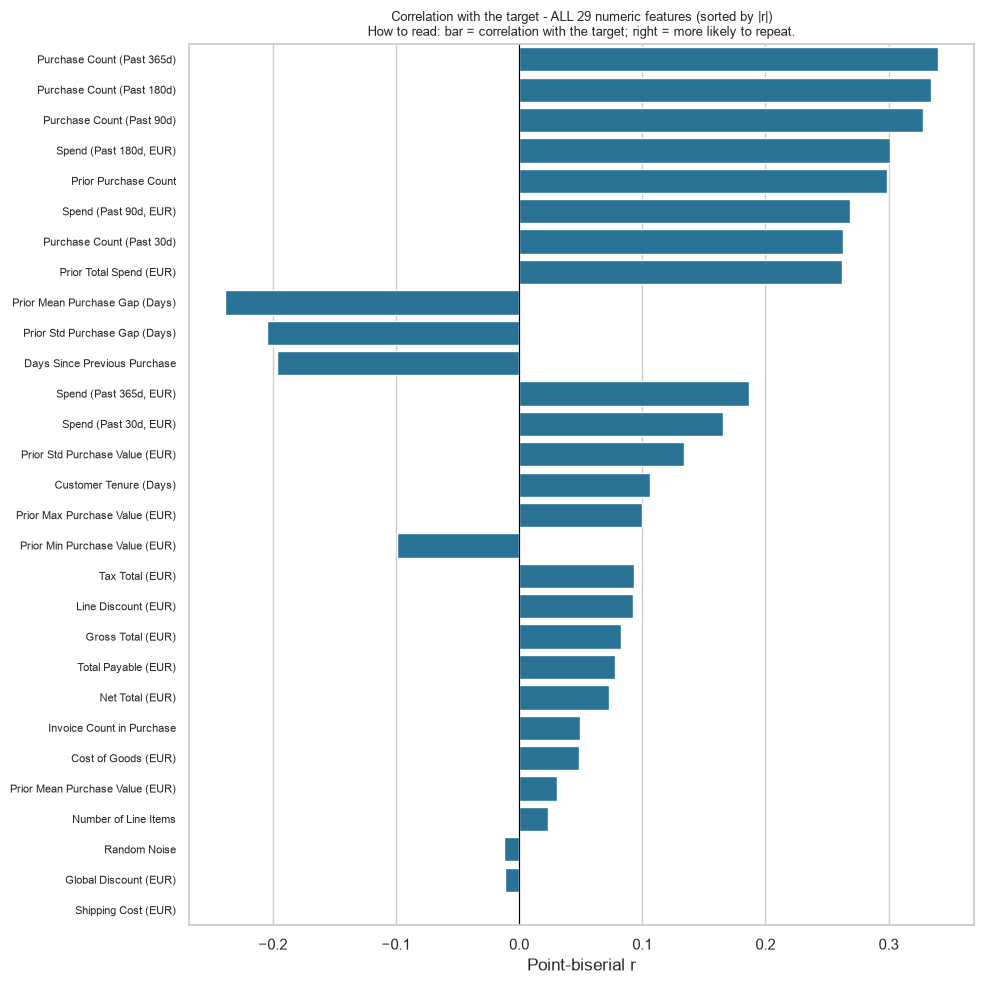

In [13]:
rows = []
for col in numeric_cols:
    if col == "random_noise":
        valid = train.loc[train[col] < 1e8, [col, TARGET]].dropna()
    else:
        valid = train.loc[(train[col] >= 0) & (train[col] < 1e8), [col, TARGET]].dropna()
    if valid[col].nunique()<2:
        continue
    pb = pointbiserialr(valid[TARGET], valid[col])
    rows.append({"feature": col, "r": pb.statistic, "|r|": abs(pb.statistic),
                 "p_value": pb.pvalue, "n_used": len(valid)})

assoc = pd.DataFrame(rows).sort_values("|r|", ascending=False).reset_index(drop=True)
assoc.insert(0, "label", [clean_label(f) for f in assoc["feature"]])
assoc = assoc.set_index("label")
print(f"Numeric association with target - all {len(assoc)} features (point-biserial r)")
display(assoc.round(4))

fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(data=assoc, y="label", x="r", orient="h", color=PLOT_BLUE, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Correlation with the target - ALL {len(assoc)} numeric features (sorted by |r|)")
ax.set_xlabel("Point-biserial r")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: bar = correlation with the target; right = more likely to repeat.")
plt.savefig(FIG_DIR / "nb01_04_association_numeric.png", dpi=200)
plt.tight_layout()
plt.show()

This analysis shows that historical purchasing features (counts and spends) have the strongest association with the target, mainly the purchases counts over the last 90, 180 and 365 days. In contrast, purchase gaps and `days_since_previous_purchase` show negative correlations, perhaps because customers with longer intervals between purchases are less likely to return within 90 days.

Features related to purchase amounts show weak correlations, while `random_noise`, `Total Desc_ Global` and `Total Portes` show non-significant linear associations. We can conclude that historical purchasing frequency appears to be more informative than individual transaction characteristics.

### Cell 14 - Correlation among numeric features:
Analyse linear relationships between numeric features using Pearson's correlation coefficient.

A correlation heatmap is generated to visualise the strength and direction of these relationships. We also look for pairs of features with an absolute coefficient of at least 0.80, which are presented in a separate table to highlight potential cases of redundancy, important for feature selection.

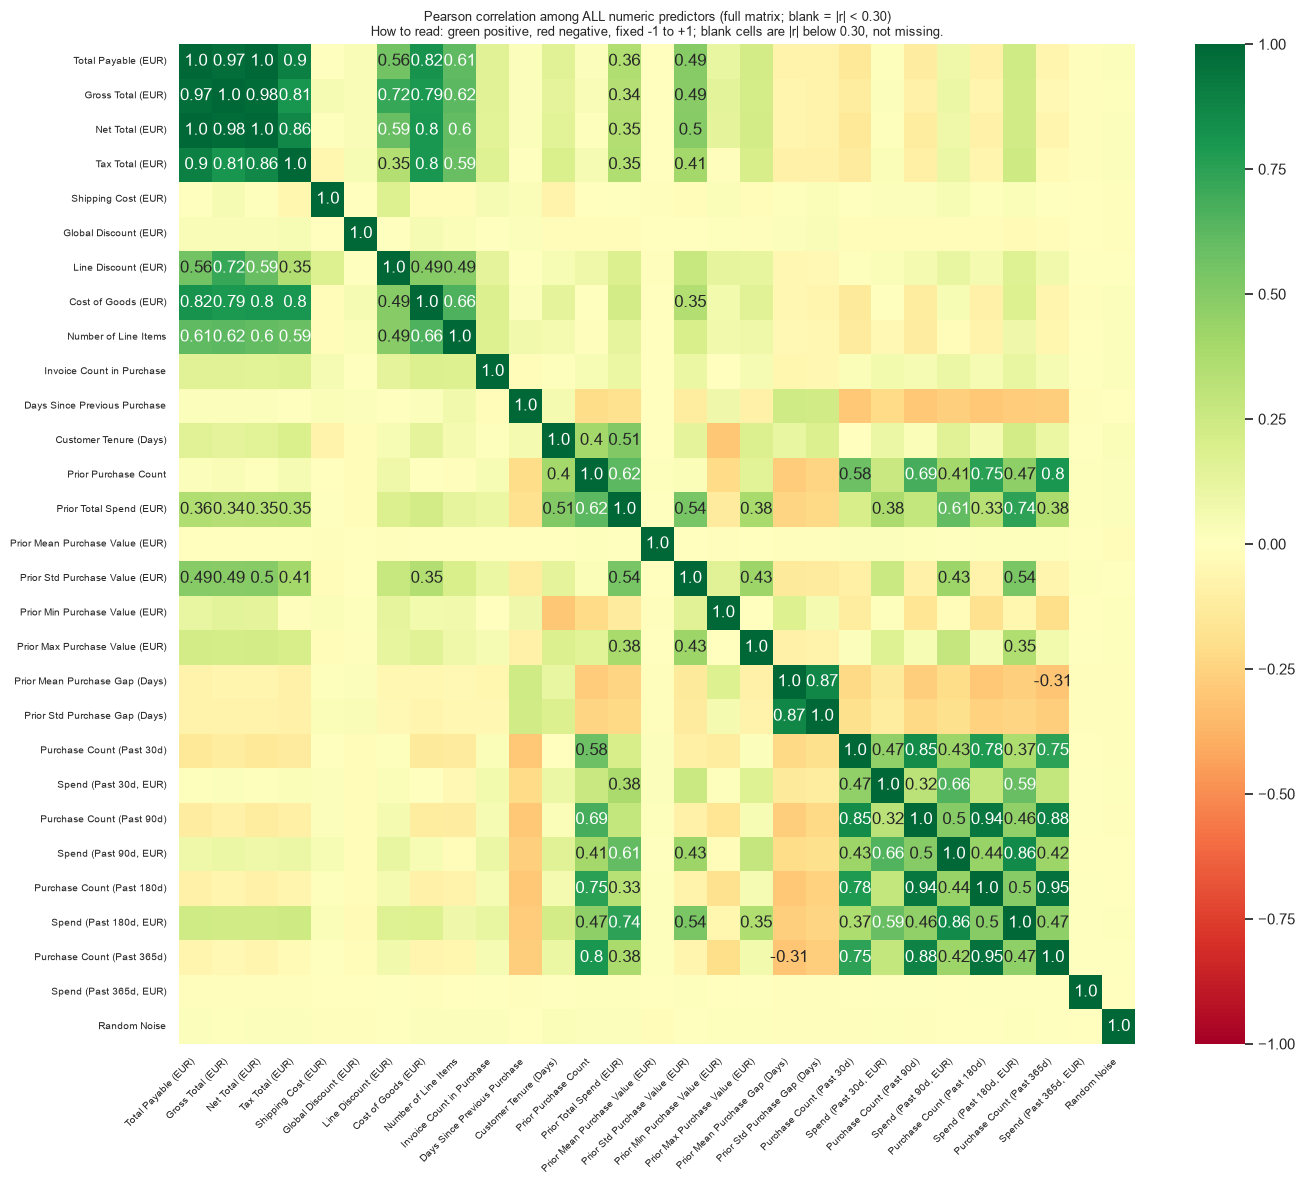


Predictor pairs with |Pearson r| >= 0.80: 16


label_1,label_2,feature_1,feature_2,pearson_r
Total Payable (EUR),Net Total (EUR),Total a Pagar,Total Liquido,0.996281
Gross Total (EUR),Net Total (EUR),Total Bruto,Total Liquido,0.984241
Total Payable (EUR),Gross Total (EUR),Total a Pagar,Total Bruto,0.974769
Purchase Count (Past 180d),Purchase Count (Past 365d),purchase_count_180d,purchase_count_365d,0.954484
Purchase Count (Past 90d),Purchase Count (Past 180d),purchase_count_90d,purchase_count_180d,0.935421
Total Payable (EUR),Tax Total (EUR),Total a Pagar,Total Imp_,0.900587
Purchase Count (Past 90d),Purchase Count (Past 365d),purchase_count_90d,purchase_count_365d,0.883039
Prior Mean Purchase Gap (Days),Prior Std Purchase Gap (Days),prior_mean_gap_days,prior_std_gap_days,0.871760
Net Total (EUR),Tax Total (EUR),Total Liquido,Total Imp_,0.859783
"Spend (Past 90d, EUR)","Spend (Past 180d, EUR)",spend_90d,spend_180d,0.856360


In [14]:
corr = train[numeric_cols].corr(numeric_only=True)

CORR_ANNOT_THRESH = 0.30
annot_txt = corr.round(2).astype(str)
annot_txt = annot_txt.mask(corr.abs() < CORR_ANNOT_THRESH, "")
corr_lbl = corr.copy()
corr_lbl.index = [clean_label(c) for c in corr_lbl.index]
corr_lbl.columns = [clean_label(c) for c in corr_lbl.columns]
annot_lbl = annot_txt.copy()
annot_lbl.index = corr_lbl.index
annot_lbl.columns = corr_lbl.columns

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_lbl, annot=annot_lbl, fmt="", vmin=-1, vmax=1, cmap="RdYlGn", ax=ax)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=7)
ax.set_title(f"Pearson correlation among ALL numeric predictors (full matrix; blank = |r| < {CORR_ANNOT_THRESH:.2f})")
guide(ax, "How to read: green positive, red negative, fixed -1 to +1; blank cells are |r| below 0.30, not missing.")
plt.savefig(FIG_DIR / "nb01_05_correlation_heatmap.png", dpi=200)
plt.tight_layout()
plt.show()

cols = corr.columns.tolist()
pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        v = corr.loc[a, b]
        if pd.notna(v) and abs(v) >= 0.80:
            pairs.append({"feature_1": a, "feature_2": b, "pearson_r": v})
pairs_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"])
if len(pairs_df):
    pairs_df = pairs_df.sort_values("pearson_r", key=abs, ascending=False)
    pairs_df.insert(0, "label_1", [clean_label(c) for c in pairs_df["feature_1"]])
    pairs_df.insert(1, "label_2", [clean_label(c) for c in pairs_df["feature_2"]])
print(f"\nPredictor pairs with |Pearson r| >= 0.80: {len(pairs_df)}")
if len(pairs_df):
    display(pairs_df.style.hide(axis="index"))
else:
    print("none")

The correlation heatmap shows 2 big groups of strongly positively correlated features: purchase amounts and prior purchase counts and spends. Regarding the most negative correlations (r ≈ -0.3), the focus shifts to purchase gaps and purchase frequency. As mentioned earlier, this suggests that customers with longer intervals between purchases tend to purchase less frequently.

We identified 16 pairs of numeric features with strong linear relationships (|r| ≥ 0.8). The strongest correlations are found among features related to purchase amounts, particularly `Total a Pagar`, `Total Liquido` and `Total Bruto` (r > 0.97). Purchase counts and spends over time periods also show strong positive correlations, especially between `purchase_count_180d` and `purchase_count_365d` (r = 0.95), which is expected given their overlapping periods. This exploration should be considered during feature selection, in notebook 3.

### Cell 15 - Correlation between categorical features and the target:
Measure association for the categorical features and show where the repeat purchase rate (`repeat_purchase_90d`=1) actually moves.

The features are ranked by their association strength using Cramér's V from chi-squared contigency tables. Bar charts are used to compare the repeat purchase rates across their different categories. Each bar includes the number of observations in that category and the dashed line represents the overall repeat purchase rate, allowing us to identify categories with above higher rate than that baseline. For readability, only a maximum of 12 levels per feature are displayed.

Categorical association with target (Cramér's V) - all 6 features


,feature,levels,Cramér's V
label,,,
Transport Method,transport_method,80,0.289910
Payment Method,payment_type,9,0.237641
Salesperson Code,salesperson,9,0.203331
Commercial Zone,commercial_zone,5,0.063756
Warehouse Location,warehouse,2,0.026641
Document Series,document_series,3,0.002924


Transport Method has 80 levels: the 12 most frequent are plotted, all 80 are listed in Cell 12


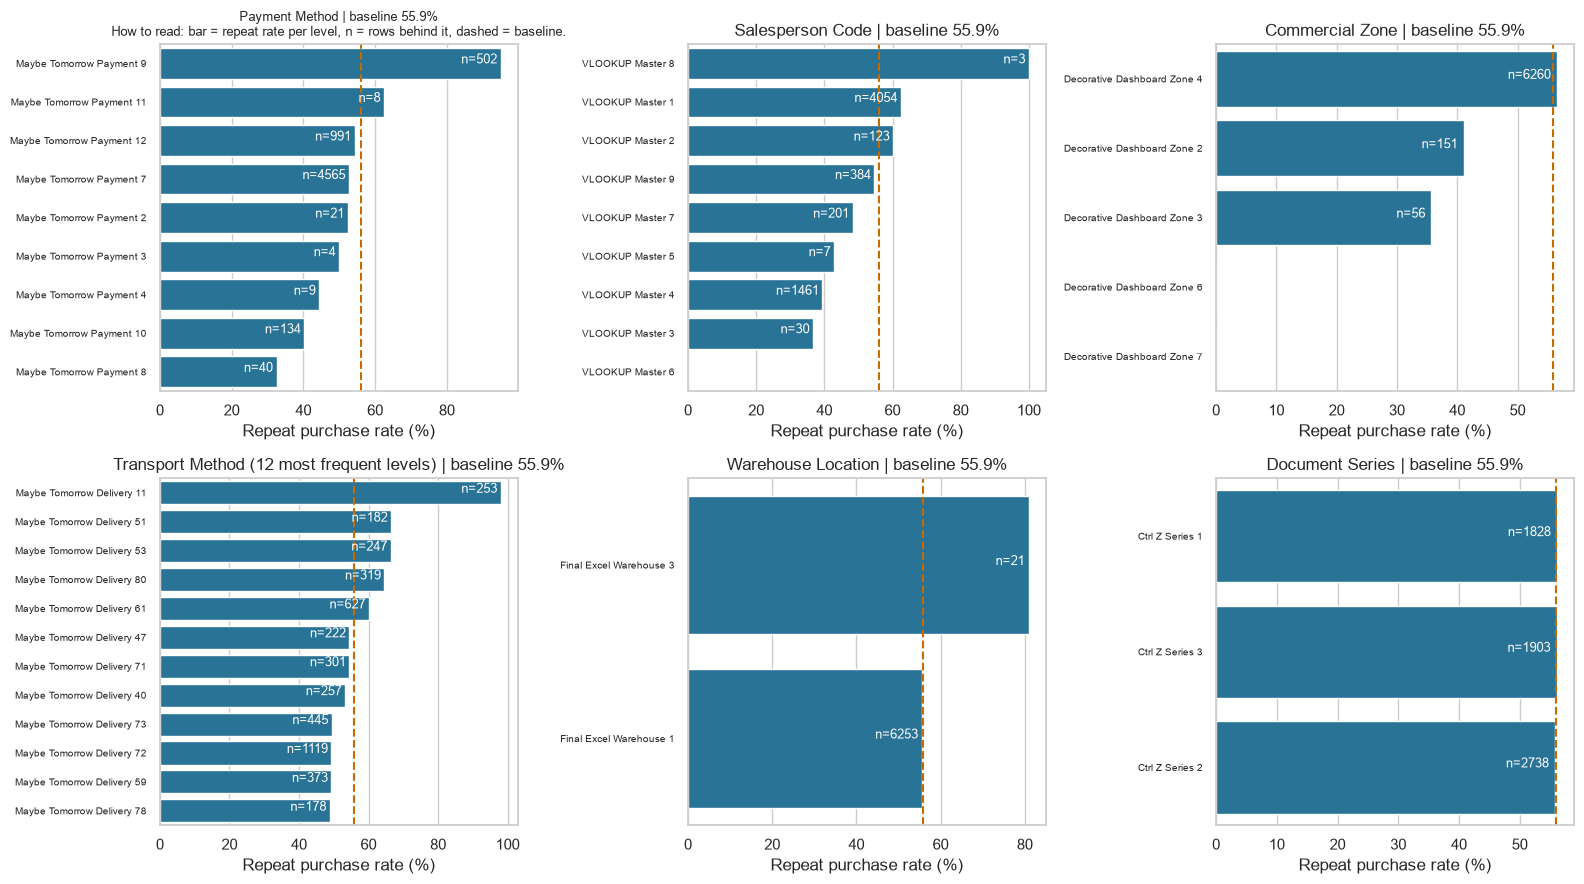

In [15]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    return association(table.values, method="cramer", correction=True)


cat_rows = []
for col in categorical_cols:
    valid = train[[col, TARGET]].dropna()
    cat_rows.append({"feature": col, "levels": int(train[col].nunique()),
                     "Cramér's V": cramers_v(valid[col], valid[TARGET])})
cat_df = pd.DataFrame(cat_rows).sort_values("Cramér's V", ascending=False)
cat_df.insert(0, "label", [clean_label(c) for c in cat_df["feature"]])
cat_df = cat_df.set_index("label")
print(f"Categorical association with target (Cramér's V) - all {len(cat_df)} features")
display(cat_df)

base = train[TARGET].mean() * 100
PANEL_LEVEL_CAP = 12
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for k, (ax, col) in enumerate(zip(axes.ravel(), categorical_cols)):
    rate = train.groupby(col)[TARGET].mean() * 100
    nsup = train[col].value_counts()
    tbl = pd.DataFrame({"n": nsup, "rate %": rate}).dropna()
    capped = len(tbl) > PANEL_LEVEL_CAP
    if capped:
        tbl = tbl.sort_values("n", ascending=False).head(PANEL_LEVEL_CAP)
    tbl = tbl.sort_values("rate %", ascending=False)
    sns.barplot(x=tbl["rate %"].values, y=tbl.index.astype(str), orient="h", color=PLOT_BLUE, ax=ax)
    for i, (r, n) in enumerate(zip(tbl["rate %"].values, tbl["n"].values)):
        ax.text(r - 1, i, f"n={int(n)}", ha="right", fontsize=9, color="white")
    ax.axvline(base, color=PLOT_ORANGE, linestyle="--")
    ax.set_title("{}{} | baseline {:.1f}%".format(
        clean_label(col),
        " ({} most frequent levels)".format(PANEL_LEVEL_CAP) if capped else "", base))
    ax.set_xlabel("Repeat purchase rate (%)")
    ax.set_ylabel("")
    plt.setp(ax.get_yticklabels(), fontsize=7)
    if capped:
        print(f"{clean_label(col)} has {train[col].nunique()} levels: the {PANEL_LEVEL_CAP} most frequent are plotted, all {train[col].nunique()} are listed in Cell 12")
guide(axes.ravel()[0], "How to read: bar = repeat rate per level, n = rows behind it, dashed = baseline.")
plt.savefig(FIG_DIR / "nb01_06_categorical_rates.png", dpi=200)
plt.tight_layout()
plt.show()

The categorical correlation analysis shows that `transport_method` has the strongest association with the target (Cramér's V = 0.290), followed by `payment_type` (0.238) and `salesperson` (0.203). However, there is a gap between these three features and the rest: `commercial_zone`, `warehouse` and `document_series` have almost zero correlation. The bar charts also reveal only 4 out of 6 features had levels that significantly exceeded the baseline (`payment_type`, `salesperson`, `transport_method`, `warehouse`). These differences should be interpreted carefully, particularly for categories with few observations. For example, in the `salesperson` feature, all customers served by VLOOKUP Master 8 repeated purchases, but there were only 3 observations.

### Cell 16 - Customer metadata:
Explore if customers features in `clientes` dataset could provide additional information for predicting repeat purchases.

The dataset structure and feature cardinality are examined, along with the overlap of customers between `train` and `test` datasets. `clientes` dataset is merged to the `train` data through `customer_id` and repeat purchase rates are compared across all customer features. To ensure more reliable analysis, only features with at most 40 distinct levels and containing at least 100 observations are considered. The results are presented in tables and bar charts with the overall repeat purchase rate as previously mentioned used as a baseline, to evaluate the potential relevance of these features for the model.

Clientes dataset profile:
 rows / unique customer_id: 1143 / 1143
 registration year range  : 2015 - 2026

Attribute cardinality (nunique):


,label,n_unique
customer_id,Customer ID,1143
country_or_region,Country / Region,11
commercial_region,Commercial Region,37
island,Island,10
municipality,Municipality,183
city,City,417
postal_area,Postal Area,271
postal_code,Postal Code,828
street,Street,511
address,Address,1120



Join coverage on customer_id:
 train rows matched in clientes  : 100.0%
 test rows matched in clientes   : 100.0%
 customers in BOTH train and test: 184

Attributes analysed (rule: at least one value present and <= 40 distinct levels):
 analysed : ['Country / Region', 'Commercial Region', 'Island', 'Customer Since (Year)']
 excluded : ['Municipality', 'City', 'Postal Area', 'Postal Code', 'Street', 'Address', 'Customer Type', 'Company Name']
 -> excluded columns are free text / near-unique identifiers (city, street, address, postal_code, company_name, ...) or fully empty (customer_type)
they are not model inputs, and notebook 2 treats them as identifiers, not as features.

Country / Region [raw: country_or_region]:
 2 of 7 levels have n >= 100; those levels cover 99.7% of joined rows


,n,rate %,dev_pp
country_or_region,,,
Country CT10: Land of The Final Version,6321,56.5,0.6
Country CT5: Land of The Final Version,194,39.2,16.7



Commercial Region [raw: commercial_region]:
 9 of 32 levels have n >= 100; those levels cover 93.2% of joined rows


,n,rate %,dev_pp
commercial_region,,,
Region RG24: We Will See Later,235,94.5,38.5
Region RG23: We Will See Later,564,82.4,26.5
Region RG27: We Will See Later,194,64.9,9.0
Region RG18: We Will See Later,368,62.0,6.0
Region RG17: We Will See Later,4109,51.9,4.1
Region RG29: We Will See Later,214,50.5,5.5
Region RG31: We Will See Later,165,46.1,9.9
Region RG9: We Will See Later,119,44.5,11.4
Region RG28: We Will See Later,120,44.2,11.8



Island [raw: island]:
 9 of 10 levels have n >= 100; those levels cover 66.0% of joined rows


,n,rate %,dev_pp
island,,,
Island IS3: The Pivot Archipelago,260,62.7,6.8
Island IS4: The Pivot Archipelago,629,57.1,1.2
Island IS8: The Pivot Archipelago,839,52.9,3.0
Island IS6: The Pivot Archipelago,564,52.5,3.4
Island IS5: The Pivot Archipelago,506,51.8,4.1
Island IS9: The Pivot Archipelago,204,51.5,4.5
Island IS7: The Pivot Archipelago,829,49.8,6.1
Island IS1: The Pivot Archipelago,375,42.4,13.5
Island IS2: The Pivot Archipelago,107,32.7,23.2



Customer Since (Year) [raw: customer_since_year]:
 9 of 10 levels have n >= 100; those levels cover 99.6% of joined rows


,n,rate %,dev_pp
customer_since_year,,,
2017,885,66.8,10.9
2023,108,60.2,4.3
2015,3573,59.5,3.6
2016,605,56.7,0.8
2020,273,49.1,6.8
2019,278,42.8,13.1
2021,208,36.5,19.4
2018,467,34.9,21.0
2022,111,25.2,30.7


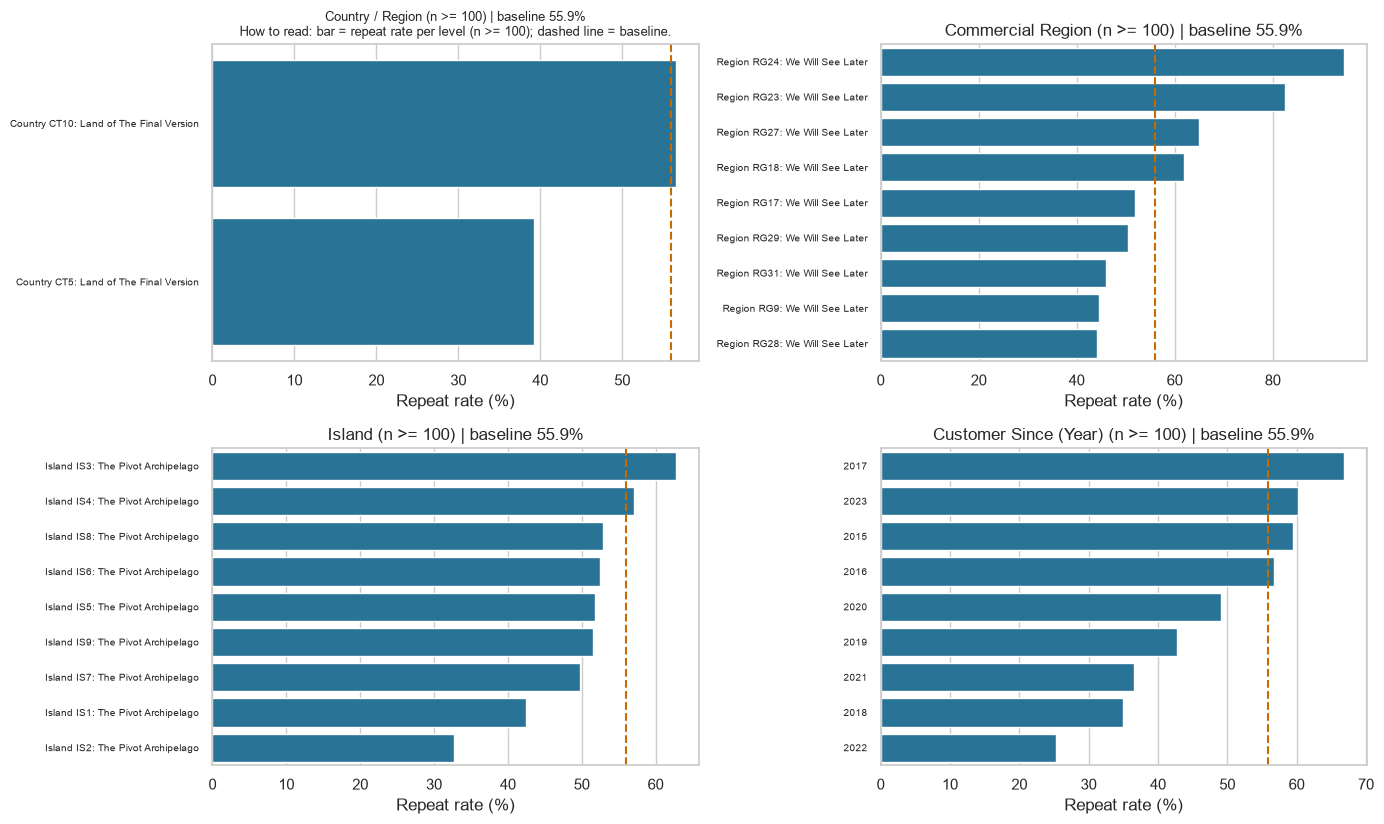

  Country / Region            : most deviating trusted level = Country CT5: Land of The Final Version | n = 194 | rate = 39.2% | dev = 16.7 pp
  Commercial Region           : most deviating trusted level = Region RG24: We Will See Later | n = 235 | rate = 94.5% | dev = 38.5 pp
  Island                      : most deviating trusted level = Island IS2: The Pivot Archipelago | n = 107 | rate = 32.7% | dev = 23.2 pp
  Customer Since (Year)       : most deviating trusted level = 2022 | n = 111 | rate = 25.2% | dev = 30.7 pp


In [16]:
print("Clientes dataset profile:")
print(" rows / unique customer_id:", len(clientes), "/", clientes["customer_id"].nunique())
print(" registration year range  :", int(clientes["customer_since_year"].min()), "-", int(clientes["customer_since_year"].max()))
print("\nAttribute cardinality (nunique):")
card = clientes.nunique().to_frame("n_unique")
card.insert(0, "label", [clean_label(c) for c in card.index])
display(card)

train_cov = train["customer_id"].isin(clientes["customer_id"]).sum() / len(train) * 100
test_cov = test["customer_id"].isin(clientes["customer_id"]).sum() / len(test) * 100
overlap = train.loc[train["customer_id"].isin(test["customer_id"]), "customer_id"].nunique()
print("\nJoin coverage on customer_id:")
print(f" train rows matched in clientes  : {train_cov:.1f}%")
print(f" test rows matched in clientes   : {test_cov:.1f}%")
print(" customers in BOTH train and test:", overlap)

train_merged = train.set_index("customer_id").join(clientes.set_index("customer_id")).reset_index()
base = train[TARGET].mean() * 100
MIN_GROUP = 100 
MAX_LEVELS = 40


def rate_table(col):
    rate = train_merged.groupby(col)[TARGET].mean() * 100
    tbl = pd.DataFrame({"n": train_merged[col].value_counts(), "rate %": rate})
    tbl["dev_pp"] = (tbl["rate %"] - base).abs()
    return tbl[tbl["n"] >= MIN_GROUP]


meta_cols = [c for c in clientes.columns
             if c != "customer_id" and clientes[c].notna().any()
             and clientes[c].nunique() <= MAX_LEVELS]
skipped = [c for c in clientes.columns if c != "customer_id" and c not in meta_cols]
print(f"\nAttributes analysed (rule: at least one value present and <= {MAX_LEVELS} distinct levels):")
print(" analysed :", [clean_label(c) for c in meta_cols])
print(" excluded :", [clean_label(c) for c in skipped])
print(" -> excluded columns are free text / near-unique identifiers (city, street, address, postal_code, company_name, ...) or fully empty (customer_type)")
print("they are not model inputs, and notebook 2 treats them as identifiers, not as features.")

tables = {}
for col in meta_cols:
    tbl = rate_table(col)
    if not len(tbl):
        print(f"\n {clean_label(col)} [raw: {col}] === no level reaches n >= {MIN_GROUP}")
        continue
    tables[col] = tbl
    print(f"\n{clean_label(col)} [raw: {col}]:")
    print(f" {len(tbl)} of {int(train_merged[col].nunique())} levels have n >= {MIN_GROUP}; those levels cover {tbl['n'].sum() / len(train_merged) * 100:.1f}% of joined rows")
    display(tbl.sort_values("rate %", ascending=False).round(1))

show_cols = list(tables)
n_panels = len(show_cols)
n_cols = 2 if n_panels > 2 else max(n_panels, 1)
n_rows = -(-n_panels // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4.2 * n_rows))
axes = list(axes.ravel()) if n_panels > 1 else [axes]
for ax, col in zip(axes, show_cols):
    tbl = tables[col].sort_values("rate %", ascending=False)
    sns.barplot(x=tbl["rate %"].values, y=tbl.index.astype(str), orient="h", color=PLOT_BLUE, ax=ax)
    ax.axvline(base, color=PLOT_ORANGE, linestyle="--")
    ax.set_title(f"{clean_label(col)} (n >= {MIN_GROUP}) | baseline {base:.1f}%")
    ax.set_xlabel("Repeat rate (%)")
    ax.set_ylabel("")
    plt.setp(ax.get_yticklabels(), fontsize=7)
guide(axes[0], "How to read: bar = repeat rate per level (n >= 100); dashed line = baseline.")
plt.savefig(FIG_DIR / "nb01_07_clientes_attributes.png", dpi=200)
plt.tight_layout()
plt.show()

for col, tbl in tables.items():
    top_lvl = tbl["dev_pp"].idxmax()
    print(f"  {clean_label(col):28s}: most deviating trusted level = {top_lvl} | n = {int(tbl.loc[top_lvl, 'n'])} | rate = {tbl.loc[top_lvl, 'rate %']:.1f}% | dev = {tbl.loc[top_lvl, 'dev_pp']:.1f} pp")

The analysis of the `clientes` dataset confirms that each of the 1143 customers has a unique identifier with 100% coverage in both `train` and `test`, 184 customers appear in both datasets.

Repeat purchase rates show considerable differences across customer features when compared to the baseline. As we have seen, `commercial_region` attribute shows the greatest variation, with rates ranging from 44.2% to 94.5% in sufficiently represented features. `customer_since_year` (25.2%–66.8%) and `island` (32.7%–62.7%) also show wide variations. This suggests that customer metadata can provide useful predictive information for the model, supported by the integration of specific features during preprocessing and feature selection.

### Cell 17 - Train versus test:
Identify differences between `train` and `test` numeric feature distributions (**data drift**)

For each feature, the means are compared using percentage differences and differences standardised by the training standard deviation. `purchase_date` ranges are also examined to check their temporal coverage. We visualize the distributions using standardised boxplots (`train` z-scores, clipped to [-4, 4] as done previously). Histograms are presented for the 2 features with the largest standardised mean differences, providing a more detailed comparison of their distributions.

Train -> test shift for all numeric features (sorted by |std_diff|):


,train_mean,test_mean,train_std,mean_diff %,std_diff,abs_std_diff
label,,,,,,
Customer Tenure (Days),1111.38,2448.73,923.19,120.33,1.45,1.45
Prior Total Spend (EUR),18908.35,49431.58,31130.87,161.43,0.98,0.98
Line Discount (EUR),112.47,261.87,289.99,132.84,0.52,0.52
Prior Purchase Count,23.46,42.91,38.34,82.92,0.51,0.51
Prior Std Purchase Value (EUR),737.47,1032.08,666.26,39.95,0.44,0.44
Gross Total (EUR),886.15,1322.44,1327.64,49.23,0.33,0.33
"Spend (Past 180d, EUR)",2650.60,3879.46,4020.27,46.36,0.31,0.31
Prior Max Purchase Value (EUR),2946.38,4609.24,5901.55,56.44,0.28,0.28
Net Total (EUR),773.34,1059.10,1136.36,36.95,0.25,0.25



Purchase_date coverage:
 train: 2015-07-11 -> 2025-02-15
 test : 2025-05-24 -> 2026-10-06


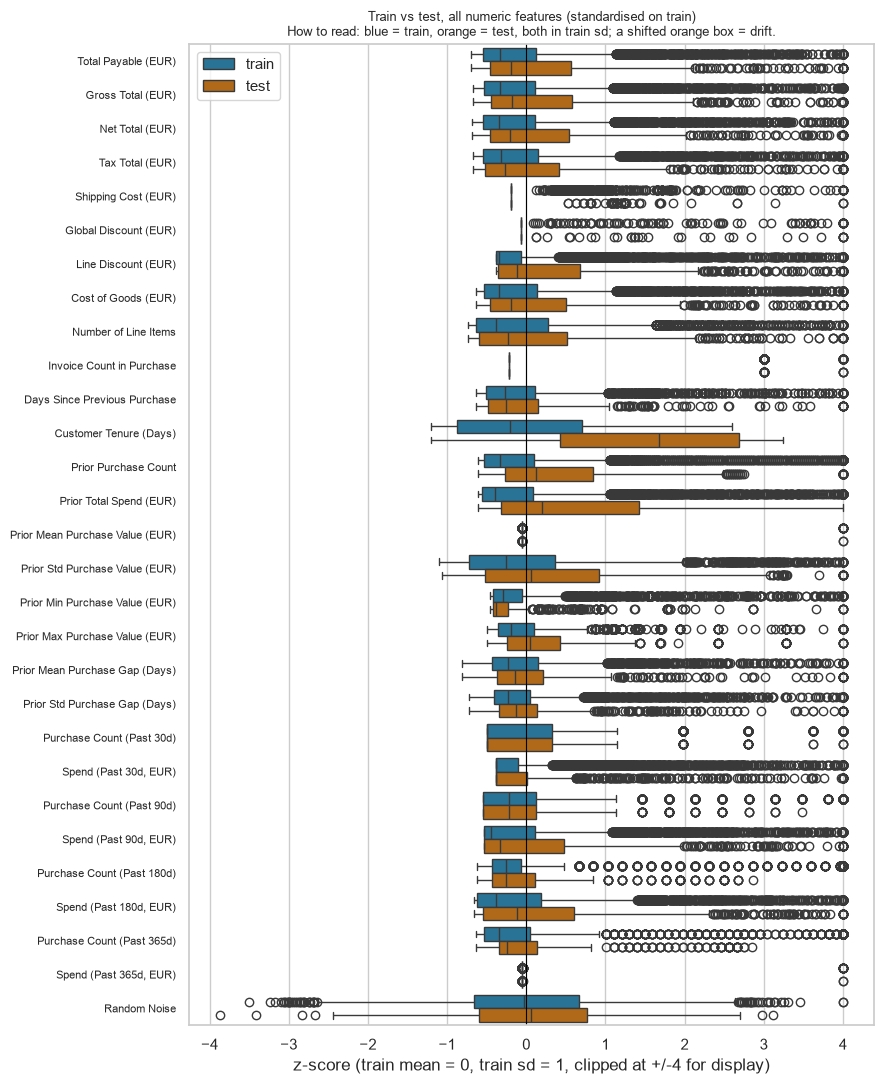


Overlaid histograms for the two largest |std_diff|: ['Customer Tenure (Days)', 'Prior Total Spend (EUR)']
Note: test holds ~6.6x fewer rows than train, so compare distribution shapes, not heights.


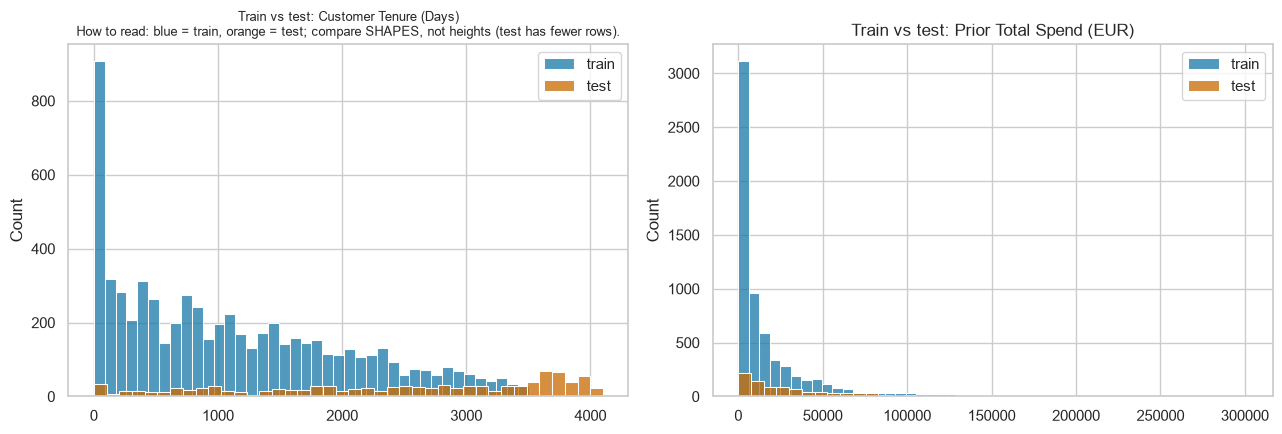

In [17]:
shift = pd.DataFrame({"train_mean": train[numeric_cols].mean(), "test_mean": test[numeric_cols].mean(), "train_std": train[numeric_cols].std()})
shift["mean_diff %"] = (shift["test_mean"] - shift["train_mean"]) / shift["train_mean"].abs().replace(0, np.nan) * 100
shift["std_diff"] = (shift["test_mean"] - shift["train_mean"]) / shift["train_std"].replace(0, np.nan)
shift["abs_std_diff"] = shift["std_diff"].abs()
shift = shift.sort_values("abs_std_diff", ascending=False)
shift.insert(0, "label", [clean_label(c) for c in shift.index])
print("Train -> test shift for all numeric features (sorted by |std_diff|):")
display(shift.set_index("label").style.format("{:.2f}"))

print("\nPurchase_date coverage:")
print(" train:", train["purchase_date"].dropna().min(), "->", train["purchase_date"].dropna().max())
print(" test :", test["purchase_date"].dropna().min(), "->", test["purchase_date"].dropna().max())


zt = ((train[numeric_cols] - mu) / sd).clip(-4, 4)
ze = ((test[numeric_cols] - mu) / sd).clip(-4, 4)
both = pd.concat([zt.assign(split="train"), ze.assign(split="test")])
both_long = pd.melt(both, id_vars="split", var_name="feature", value_name="z_score")
both_long["label"] = [clean_label(f) for f in both_long["feature"]]
fig, ax = plt.subplots(figsize=(9, 11))
sns.boxplot(data=both_long, y="label", x="z_score", hue="split", orient="h", palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Train vs test, all numeric features (standardised on train)")
ax.set_xlabel("z-score (train mean = 0, train sd = 1, clipped at +/-4 for display)")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
ax.legend()
guide(ax, "How to read: blue = train, orange = test, both in train sd; a shifted orange box = drift.")
plt.savefig(FIG_DIR / "nb01_08_drift_boxplots.png", dpi=200)
plt.tight_layout()
plt.show()

drift_cols = shift.index[:2].tolist()
print("\nOverlaid histograms for the two largest |std_diff|:", [clean_label(c) for c in drift_cols])
print(f"Note: test holds ~{len(train) / len(test):.1f}x fewer rows than train, so compare distribution shapes, not heights.")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, drift_cols):
    sns.histplot(train[col].dropna(), bins=40, color=PLOT_BLUE, label="train", ax=ax)
    sns.histplot(test[col].dropna(), bins=40, color=PLOT_ORANGE, label="test", ax=ax)
    ax.set_title("Train vs test: " + clean_label(col))
    ax.set_xlabel("")
    ax.legend()
guide(axes[0], "How to read: blue = train, orange = test; compare SHAPES, not heights (test has fewer rows).")
plt.savefig(FIG_DIR / "nb01_09_drift_histograms.png", dpi=200)
plt.tight_layout()
plt.show()

The comparison above shows the highest shifts occur in `customer_tenure_days` (+120.33% in mean, sd=1.45), `prior_total_spend` (+161.43% in mean, sd=0.98) and `Total Desc_ Linha` (+132.4% in mean, sd=0.58).

The standardised boxplots confirm these shifts, with the `test` dataset generally showing higher medians and wider IQR ranges, mainly for features related to purchase amounts and spends in time periods. Features such as `random_noise`, `Total Desc_ Global` and prior purchase gaps features show similar distributions across both datasets. Many monetary features, such as `Total a Pagar`. have numerous extremely high observations in both datasets, reflecting their strong right-skewness.

Additionally, the purchase dates confirm that `test` contains more recent observations (2025–2026) than `train` (2015–2025), which may explain the observed differences. Through this analysis, we notice that there may be data drift, with a particular focus on customer history and spending features, and that should considered when evaluating the model's performance to predict future purchases.

### Cell 18 - Summary:

In [18]:
n_missing_cols = int((train.isna().sum() > 0).sum())
print("Data Exploration summary:")
print(f"1. Size: train={len(train)} rows, test={len(test)} rows; {train['customer_id'].nunique()} unique customers.")
print(f"2. Balance: {share.loc[1]*100:.1f}% positive / {share.loc[0]*100:.1f}% negative (minority-majority ratio { balance_ratio:.2f}) -> close to  balanced; majority baseline {baseline*100:.1f}%.")
print(f"3. Missing: {n_missing_cols} columns contain nulls; {int((row_missing == row_missing.max()).sum())} train rows are structurally empty.")
print(f"4. Invalid values: 10^9 placeholders and impossible negatives.")
print(f"5. Strongest numeric associations: {', '.join(clean_label(f) for f in assoc.head(3)['feature'])}.")
_cramer_s_v = "Cramér's V"
print(f"6. Strongest categorical associations: {clean_label(cat_df['feature'].tolist()[0])} (Cramér's V={cat_df[_cramer_s_v].tolist()[0]:.3f}).")
print(f"7. Redundant predictor pairs (|r| >= 0.80): {len(pairs_df)}.")
best_col, best_dev = max(((c, t["dev_pp"].max()) for c, t in tables.items()), key=lambda t: t[1])
print(f"8. Clients dataset carries real association: largest trusted deviation {best_dev:.1f} pp in {clean_label(best_col)}.")
print("9. Train vs test drift exists and points to temporal/grouped validation.")
print(f"10. {clean_label('random_noise')} is a planted noise column (near-zero association).")


print("---------")
train.to_csv(DATA_DIR / "train_raw.csv", index=False)
test.to_csv(DATA_DIR / "test_raw.csv", index=False)
clientes.to_csv(DATA_DIR / "clientes_raw.csv", index=False)
print("Saved to", DATA_DIR)
print("  train_raw.csv, test_raw.csv, clientes_raw.csv")

Data Exploration summary:
1. Size: train=6534 rows, test=986 rows; 610 unique customers.
2. Balance: 55.9% positive / 44.1% negative (minority-majority ratio 0.79) -> close to  balanced; majority baseline 55.9%.
3. Missing: 36 columns contain nulls; 65 train rows are structurally empty.
4. Invalid values: 10^9 placeholders and impossible negatives.
5. Strongest numeric associations: Purchase Count (Past 365d), Purchase Count (Past 180d), Purchase Count (Past 90d).
6. Strongest categorical associations: Transport Method (Cramér's V=0.290).
7. Redundant predictor pairs (|r| >= 0.80): 16.
8. Clients dataset carries real association: largest trusted deviation 38.5 pp in Commercial Region.
9. Train vs test drift exists and points to temporal/grouped validation.
10. Random Noise is a planted noise column (near-zero association).
---------
Saved to /Users/macbookpro/NovaWorkspace/MachineLearning/FinalProject/Project/ML_Group_22/data
  train_raw.csv, test_raw.csv, clientes_raw.csv


---

## Where this notebook leaves the homework

- `data/train_raw.csv`, `data/test_raw.csv`, `data/clientes_raw.csv`: unchanged raw datasets
-  9 figures in `artifacts/figures/`

**Conclusions Notebook 2 must act on:**

| Notebook 1 finding | Action taken in Notebook 2 |
|---|---|
| 65 train rows have every transaction field null; test has none |Dropped from `train`|
| 1e9 placeholders in Prior Mean Purchase Value and Spend (365d) | Converted to NaN + invalid-value flag. Never clipped into a real number |
| Impossible negatives in Spend (365d), Days Since Previous Purchase, Prior Mean Purchase Gap| Converted to NaN + negative-value flag |
| `prior...` nulls are structural: 603 first-time buyers and statistics features related to that are undefined after a single purchase | Filled 0 **only for those rows**, with `no_purchase_history` / `single_purchase` flags|
|Categorical nulls (~4% of rows) carry no meaning | Imputed an explicit `Missing` level, which one-hot encodes into its own column |
| `transport_method` has 80 levels, 59 of them below 1% of rows|Levels below 1% of train grouped into `Other` before encoding |
| `clientes` attributes with <= 40 levels carry real association with | Joined on `customer_id` and 100% null features dropped|
|`train` `purchase_date` between 2015-2025, `test` 2025-2026 | `purchase_year` computed only for data quality assurance but **excluded from the model** (a coefficient on a year cannot extrapolate past the training range); `purchase_month` is kept for the model |
| 29 features with \|skew\| > 1.5 and high zero-inflation | `log1p` on the skewed non-negative columns before scaling |
|`random_noise` is a planted column with near-zero association|Dropped|




**Next: Notebook 2 - Clean & Preprocess**